## 1. Install packages

In [ ]:
# Only install/upgrade what's missing; leave matplotlib/numpy/pandas/scikit-learn/torch alone
# to avoid breaking Colab's pre-installed, mutually-compatible versions.
!pip install -q --upgrade transformers sentencepiece openpyxl xgboost statsmodels
# shap must be >=0.46.0 — NumPy 2.0 support landed in that release (earlier versions call
# np.obj2sctype, which NumPy 2.0 removed, and Colab now ships NumPy 2.x by default). Not
# upper-bounding the version so pip can resolve the newest build compatible with your
# Colab's current Python/NumPy versions.
!pip install -q "shap>=0.46.0" "lime==0.2.0.1"

print("Package installation complete.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 74.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 12.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Package installation complete.


## 2. Imports, seed, device, and **Bangla font registration**




In [ ]:
import os, re, time, random, warnings, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

import torch
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device :", DEVICE)

import tensorflow as tf
tf.random.set_seed(SEED)
print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))

# ---- output directories ----
OUTPUT_DIR = "outputs"
for sub in ["", "figures", "confusion_matrices", "shap", "lime", "tables", "roc_pr", "sentiment"]:
    os.makedirs(os.path.join(OUTPUT_DIR, sub), exist_ok=True)
os.makedirs("models", exist_ok=True)

# ---- Bangla font: install + register BEFORE any plotting ----
!apt-get -qq update
!apt-get -qq install -y fonts-noto-core > /dev/null 2>&1

bangla_font_path = None
for root, _, files in os.walk("/usr/share/fonts"):
    for f in files:
        if "NotoSansBengali" in f and f.endswith(".ttf"):
            bangla_font_path = os.path.join(root, f)
            break
    if bangla_font_path:
        break

if bangla_font_path:
    fm.fontManager.addfont(bangla_font_path)
    BANGLA_FONT_NAME = fm.FontProperties(fname=bangla_font_path).get_name()
    try:
        fm._load_fontmanager(try_read_cache=False)
    except Exception:
        pass

    # IMPORTANT FIX: do NOT set font.family to the Bangla font alone. "Noto Sans Bengali"
    # only contains Bengali-script glyphs — it has no Latin letters — so setting it as the
    # *sole* font breaks every piece of English text in the notebook (titles, legends, model
    # names all render as empty boxes). Matplotlib >= 3.6 supports per-character font
    # fallback when font.family is given as a LIST: it renders each character with the first
    # font in the list that actually contains that glyph. "DejaVu Sans" (matplotlib's default,
    # always available) covers Latin/digits/punctuation; the Bangla font covers Bengali script.
    # Together, mixed English+Bangla strings (e.g. plot titles, legend labels) render correctly.
    plt.rcParams["font.family"] = ["DejaVu Sans", BANGLA_FONT_NAME]
    print(f"Bangla font registered with Latin fallback: 'DejaVu Sans' + '{BANGLA_FONT_NAME}' ({bangla_font_path})")
else:
    BANGLA_FONT_NAME = None
    print("WARNING: Bangla font not found — Bangla feature names in SHAP plots may render as boxes.")

plt.rcParams["axes.unicode_minus"] = False

# [v7 FIX] E: record exact library versions for the thesis software/environment table
import sys, sklearn, matplotlib, transformers
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__,
      "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| matplotlib", matplotlib.__version__)


PyTorch device : cuda
TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Bangla font registered with Latin fallback: 'DejaVu Sans' + 'Noto Sans Bengali' (/usr/share/fonts/truetype/noto/NotoSansBengali-Regular.ttf)
Python 3.13.15 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | tensorflow 2.21.0 | torch 2.11.0+cu130 | transformers 5.20.1 | matplotlib 3.10.0


## 3. Load dataset

Upload `BSMDD_v3_textcleaned_-_21K.xlsx` when prompted (or mount Google Drive and point
`DATA_FILENAME` at the path).


In [ ]:
DATA_FILENAME = "BSMDD_v3_textcleaned_-_21K.xlsx"

if not os.path.exists(DATA_FILENAME):
    try:
        from google.colab import files
        print("Please upload the dataset file now.")
        uploaded = files.upload()
        DATA_FILENAME = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"'{DATA_FILENAME}' not found. Upload it or set DATA_FILENAME to its path.")

df_raw = pd.read_excel(DATA_FILENAME)
print("Raw shape:", df_raw.shape)
print("Raw columns:", df_raw.columns.tolist())

EXPECTED_TEXT_COL, EXPECTED_LABEL_COL = "text", "label"
if EXPECTED_TEXT_COL not in df_raw.columns or EXPECTED_LABEL_COL not in df_raw.columns:
    raise ValueError(f"Expected columns '{EXPECTED_TEXT_COL}', '{EXPECTED_LABEL_COL}' not found. "
                      f"Available columns: {df_raw.columns.tolist()}")

df = df_raw[[EXPECTED_TEXT_COL, EXPECTED_LABEL_COL]].copy()
df.columns = ["text", "label"]
df.head()


Please upload the dataset file now.


Saving bangla dataset.xlsx to bangla dataset.xlsx
Raw shape: (21910, 2)
Raw columns: ['text', 'label']


,text,label
0,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...,1
1,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...,1
2,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...,1
3,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1
4,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1


## 4. Cleaning & label provenance note




In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1], "->", df.columns.tolist())
print()
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Unique label values:", sorted(df['label'].unique().tolist()))


Rows: 21910
Columns: 2 -> ['text', 'label']

Missing values per column:
text     0
label    0
dtype: int64

Unique label values: [0, 1]


In [ ]:
n_before = len(df)
n_dup_rows = df.duplicated().sum()
n_dup_texts = df.duplicated(subset=["text"]).sum()
print(f"Duplicate rows (full-row)   : {n_dup_rows}")
print(f"Duplicate texts             : {n_dup_texts}")

dup_groups = df[df.duplicated(subset=["text"], keep=False)]
if len(dup_groups) > 0:
    inconsistent = (dup_groups.groupby("text")["label"].nunique() > 1).sum()
    print(f"Duplicate-text groups with inconsistent labels: {inconsistent}")

df = df.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)
print(f"\nRemoved {n_before - len(df)} duplicate rows. Shape after dedup: {df.shape}")

df = df.dropna(subset=["text", "label"])
print(f"Shape after dropping any missing text/label rows: {df.shape}")


Duplicate rows (full-row)   : 6
Duplicate texts             : 6
Duplicate-text groups with inconsistent labels: 0

Removed 6 duplicate rows. Shape after dedup: (21904, 2)
Shape after dropping any missing text/label rows: (21904, 2)


In [ ]:
def clean_bangla_text(text: str) -> str:
    text = str(text)
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+\.\s*", " ", text)
    text = re.sub(r"#(\w+)", " ", text)
    # [v7 FIX] B: also keep ZWNJ/ZWJ (U+200C/U+200D), which Bangla needs for forms like র‍্য
    text = re.sub(r"[^\u0980-\u09FF\u200c\u200d\s\u0964\d,.!?]", " ", text)  # keep Bangla script, digits, basic punctuation
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_bangla_text)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
print("Final dataset shape:", df.shape)
df[["clean_text", "label"]].head()


Final dataset shape: (21902, 3)


,clean_text,label
0,মানসিক শারীরিকভাবে অসুস্থ ক্লান্ত পুরো জীবন শা...,1
1,দয়া সাথে থাকুন অত্যন্ত দীর্ঘ আপনাকে পড়তে উত্...,1
2,জানতাম সাথে ভুল লোক খারাপ জীবন কাটিয়েছে সম্পূ...,1
3,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1
4,অনেটিভ ইংরেজি স্পিকারের অনুসরণ বিরক্তিকর অপ্রত...,1


## 5. Sentiment analysis




In [ ]:
from transformers import AutoTokenizer as SentTokenizerClass, AutoModelForSequenceClassification as SentModelClass

SENTIMENT_MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

sentiment_tokenizer = SentTokenizerClass.from_pretrained(SENTIMENT_MODEL_NAME)
sentiment_model = SentModelClass.from_pretrained(SENTIMENT_MODEL_NAME).to(DEVICE)
sentiment_model.eval()

raw_id2label = sentiment_model.config.id2label
print("Raw model label mapping:", raw_id2label)

def _normalize_sentiment_label(raw_label: str) -> str:
    raw_label = str(raw_label).lower()
    if "neg" in raw_label or raw_label == "label_0":
        return "Negative"
    if "neu" in raw_label or raw_label == "label_1":
        return "Neutral"
    if "pos" in raw_label or raw_label == "label_2":
        return "Positive"
    return str(raw_label)

sentiment_id2label = {i: _normalize_sentiment_label(l) for i, l in raw_id2label.items()}
print("Sentiment label mapping:", sentiment_id2label)


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Raw model label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}
Sentiment label mapping: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}


In [ ]:
@torch.no_grad()
def predict_sentiment_batch(texts, batch_size=64, max_len=128):
    all_labels = []
    for i in range(0, len(texts), batch_size):
        batch = list(texts[i:i + batch_size])
        enc = sentiment_tokenizer(
            batch, truncation=True, padding=True, max_length=max_len, return_tensors="pt"
        ).to(DEVICE)
        logits = sentiment_model(**enc).logits
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        all_labels.extend([sentiment_id2label[p] for p in preds])
    return all_labels

start = time.time()
df["Sentiment"] = predict_sentiment_batch(df["clean_text"].tolist())
print(f"Sentiment inference complete for {len(df)} rows in {time.time() - start:.1f}s")

# Free GPU memory before training the depression-detection models later
del sentiment_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

df[["clean_text", "label", "Sentiment"]].head()


KeyboardInterrupt: 

### 5.1 Overall sentiment distribution

In [ ]:
sentiment_counts = df["Sentiment"].value_counts()
sentiment_pct = (sentiment_counts / len(df) * 100).round(2)
sentiment_summary = pd.DataFrame({"Count": sentiment_counts, "Percentage": sentiment_pct})
print(sentiment_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
colors = {"Negative": "#C44E52", "Neutral": "#8172B2", "Positive": "#55A868"}
bar_colors = [colors.get(s, "#999999") for s in sentiment_counts.index]

axes[0].bar(sentiment_counts.index, sentiment_counts.values, color=bar_colors)
axes[0].set_title("Sentiment Distribution")
axes[0].set_ylabel("Count")

axes[1].pie(sentiment_counts.values, labels=sentiment_counts.index, autopct="%1.1f%%",
            colors=bar_colors, startangle=90)
axes[1].set_title("Sentiment Share")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sentiment/sentiment_distribution.png", dpi=150)
plt.show()


### 5.2 Sentiment composition by depression label



In [ ]:
SENTIMENT_ORDER = ["Negative", "Neutral", "Positive"]

composition = pd.crosstab(df["label"], df["Sentiment"]).reindex(columns=SENTIMENT_ORDER, fill_value=0)
composition_pct = composition.div(composition.sum(axis=1), axis=0) * 100

print("Counts:")
print(composition)
print("\nRow-normalized percentages:")
print(composition_pct.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
composition_pct.plot(
    kind="bar", stacked=True, ax=ax,
    color=[colors[c] for c in SENTIMENT_ORDER]
)
ax.set_title("Sentiment Composition by Depression Label")
ax.set_xlabel("Depression Label")
ax.set_ylabel("Percentage")
ax.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sentiment/sentiment_by_depression_label.png", dpi=150)
plt.show()


## 6. EDA — class balance and text length distributions

Class distribution:
label
0    10945
1    10957
Name: count, dtype: int64

Min/Max ratio: 0.999 -> Dataset is BALANCED


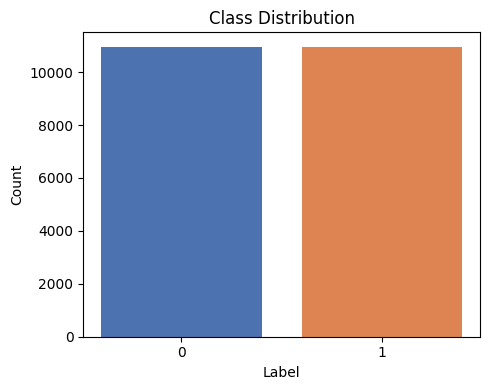

In [ ]:
class_counts = df["label"].value_counts().sort_index()
print("Class distribution:")
print(class_counts)

ratio = class_counts.min() / class_counts.max()
balance_status = "BALANCED" if ratio >= 0.8 else ("MODERATELY IMBALANCED" if ratio >= 0.5 else "IMBALANCED")
print(f"\nMin/Max ratio: {ratio:.3f} -> Dataset is {balance_status}")

plt.figure(figsize=(5, 4))
plt.bar(class_counts.index.astype(str), class_counts.values, color=["#4C72B0", "#DD8452"])
plt.title("Class Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/class_distribution.png", dpi=150)
plt.show()


Character length statistics:
count    21902.000000
mean       550.946945
std        421.869240
min          6.000000
25%        272.000000
50%        420.000000
75%        713.000000
max       4904.000000
Name: char_len, dtype: float64

Word length statistics:
count    21902.000000
mean        80.405168
std         60.474316
min          1.000000
25%         40.000000
50%         61.000000
75%        104.000000
max        704.000000
Name: word_len, dtype: float64


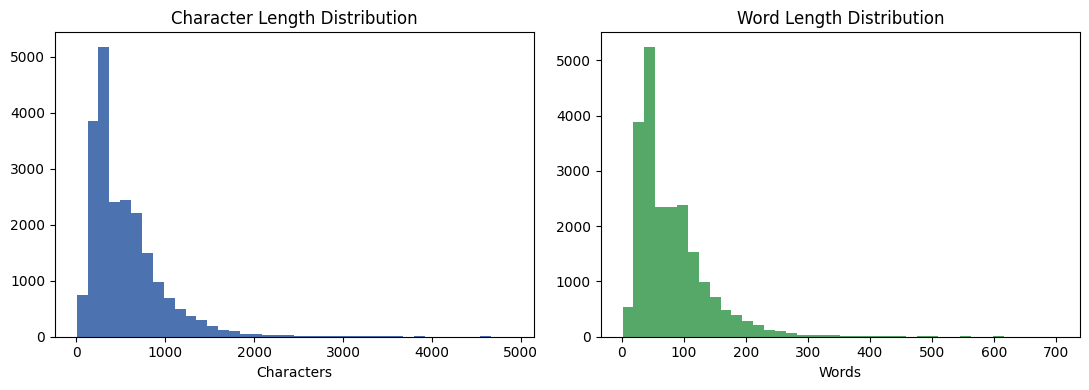

In [ ]:
df["char_len"] = df["clean_text"].str.len()
df["word_len"] = df["clean_text"].str.split().apply(len)

print("Character length statistics:")
print(df["char_len"].describe())
print("\nWord length statistics:")
print(df["word_len"].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["char_len"], bins=40, color="#4C72B0")
axes[0].set_title("Character Length Distribution")
axes[0].set_xlabel("Characters")
axes[1].hist(df["word_len"], bins=40, color="#55A868")
axes[1].set_title("Word Length Distribution")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/length_distributions.png", dpi=150)
plt.show()


## 7. Train/test split + TF-IDF (fit on train only)




In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

le = LabelEncoder()
df["label_enc"] = le.fit_transform(df["label"])
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"].values, df["label_enc"].values,
    test_size=0.2, random_state=SEED, stratify=df["label_enc"].values
)
print(f"Train size: {len(X_train_text)} | Test size: {len(X_test_text)}")
print("Train class distribution:", np.bincount(y_train))
print("Test class distribution :", np.bincount(y_test))

# [v7 FIX] A: the default token_pattern r"(?u)\b\w\w+\b" splits Bangla words at every vowel
# sign/hasanta (\w does not match them), e.g. বিষণ্ণতা -> ["ষণ", "ণত"]. Split on whitespace instead.
tfidf_vectorizer = TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=2,
                                   token_pattern=r"(?u)[^\s]+")
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)
print(f"TF-IDF train shape: {X_train_tfidf.shape} | test shape: {X_test_tfidf.shape}")

all_results = []        # collects every model's metrics for the final comparison table
trained_ml_models = {}   # name -> fitted model
prediction_lookup = {}   # name -> hard predictions on test set
score_lookup = {}        # name -> continuous scores/probabilities for the positive class (for ROC/PR)
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
POS_CLASS_IDX = 1  # index of the "positive"/depression class after label encoding


Label mapping: {np.int64(0): np.int64(0), np.int64(1): np.int64(1)}
Train size: 17521 | Test size: 4381
Train class distribution: [8756 8765]
Test class distribution : [2189 2192]
TF-IDF train shape: (17521, 8000) | test shape: (4381, 8000)


## 8. Classical ML models (with 5-fold CV + held-out test evaluation)



In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.decomposition import TruncatedSVD

def evaluate_and_log(model_name, y_true, y_pred, train_time, category, y_score=None, save_cm=True):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan

    print(f"===== {model_name} =====")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"AUC       : {auc:.4f}" if y_score is not None else "AUC       : n/a")
    print(f"Training Time: {train_time:.2f}s")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    if save_cm:
        fig, ax = plt.subplots(figsize=(4.5, 4))
        cm = confusion_matrix(y_true, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"Confusion Matrix - {model_name}")
        plt.tight_layout()
        safe_name = re.sub(r"[^\w\-]", "_", model_name)
        plt.savefig(f"{OUTPUT_DIR}/confusion_matrices/{safe_name}_cm.png", dpi=150)
        plt.show()

    all_results.append({
        "Model": model_name, "Category": category,
        "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1, "AUC": auc,
        "Training Time (s)": train_time
    })
    prediction_lookup[model_name] = y_pred
    if y_score is not None:
        score_lookup[model_name] = y_score
    return acc, prec, rec, f1, auc

def run_cv(model, X, y, name):
    scoring = ["accuracy", "f1_weighted"]
    scores = cross_validate(model, X, y, cv=cv_splitter, scoring=scoring, n_jobs=-1)
    print(f"[{name}] 5-fold CV — Accuracy: {scores['test_accuracy'].mean():.4f} "
          f"± {scores['test_accuracy'].std():.4f} | "
          f"F1: {scores['test_f1_weighted'].mean():.4f} ± {scores['test_f1_weighted'].std():.4f}")
    return scores

def get_positive_class_score(model, X):
    """Continuous score for the positive class, used for ROC/PR curves and AUC."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, POS_CLASS_IDX]
    return model.decision_function(X)  # e.g. LinearSVC

print("Evaluation helpers ready.")


Evaluation helpers ready.



--- Logistic Regression: 5-fold cross-validation on training set ---
[Logistic Regression] 5-fold CV — Accuracy: 0.8795 ± 0.0017 | F1: 0.8795 ± 0.0017
===== Logistic Regression =====
Accuracy  : 0.8813
Precision : 0.8814
Recall    : 0.8813
F1-score  : 0.8813
AUC       : 0.9441
Training Time: 0.25s

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.89      0.88      2189
           1       0.89      0.87      0.88      2192

    accuracy                           0.88      4381
   macro avg       0.88      0.88      0.88      4381
weighted avg       0.88      0.88      0.88      4381



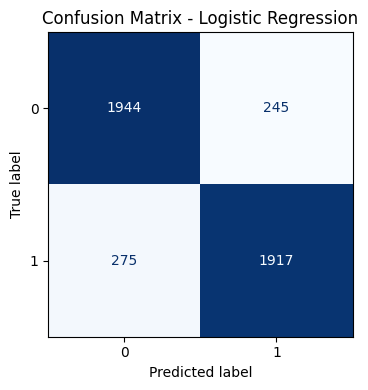


--- Random Forest: 5-fold cross-validation on training set ---
[Random Forest] 5-fold CV — Accuracy: 0.8525 ± 0.0051 | F1: 0.8525 ± 0.0051
===== Random Forest =====
Accuracy  : 0.8521
Precision : 0.8522
Recall    : 0.8521
F1-score  : 0.8521
AUC       : 0.9249
Training Time: 10.00s

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      2189
           1       0.86      0.84      0.85      2192

    accuracy                           0.85      4381
   macro avg       0.85      0.85      0.85      4381
weighted avg       0.85      0.85      0.85      4381



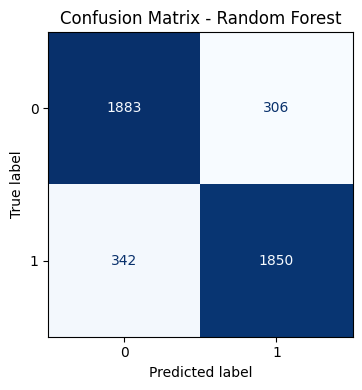


--- Decision Tree: 5-fold cross-validation on training set ---
[Decision Tree] 5-fold CV — Accuracy: 0.7614 ± 0.0050 | F1: 0.7613 ± 0.0050
===== Decision Tree =====
Accuracy  : 0.7574
Precision : 0.7574
Recall    : 0.7574
F1-score  : 0.7574
AUC       : 0.7517
Training Time: 7.29s

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.76      0.76      2189
           1       0.76      0.75      0.76      2192

    accuracy                           0.76      4381
   macro avg       0.76      0.76      0.76      4381
weighted avg       0.76      0.76      0.76      4381



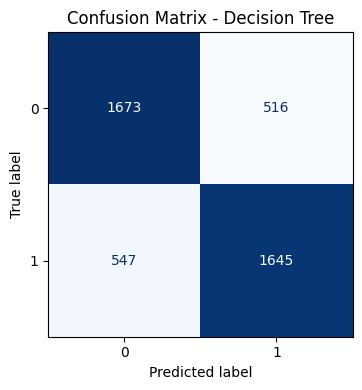


--- SVM (LinearSVC): 5-fold cross-validation on training set ---
[SVM (LinearSVC)] 5-fold CV — Accuracy: 0.8716 ± 0.0026 | F1: 0.8716 ± 0.0026
===== SVM (LinearSVC) =====
Accuracy  : 0.8719
Precision : 0.8720
Recall    : 0.8719
F1-score  : 0.8719
AUC       : 0.9373
Training Time: 0.22s

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.88      0.87      2189
           1       0.88      0.87      0.87      2192

    accuracy                           0.87      4381
   macro avg       0.87      0.87      0.87      4381
weighted avg       0.87      0.87      0.87      4381



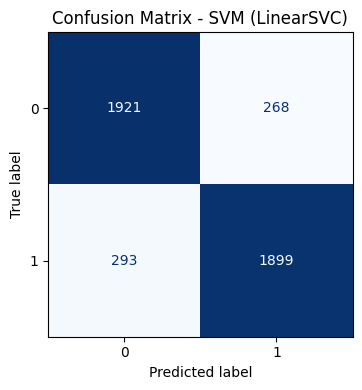


--- Naive Bayes: 5-fold cross-validation on training set ---
[Naive Bayes] 5-fold CV — Accuracy: 0.8775 ± 0.0028 | F1: 0.8774 ± 0.0028
===== Naive Bayes =====
Accuracy  : 0.8731
Precision : 0.8746
Recall    : 0.8731
F1-score  : 0.8730
AUC       : 0.9390
Training Time: 0.01s

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.84      0.87      2189
           1       0.85      0.91      0.88      2192

    accuracy                           0.87      4381
   macro avg       0.87      0.87      0.87      4381
weighted avg       0.87      0.87      0.87      4381



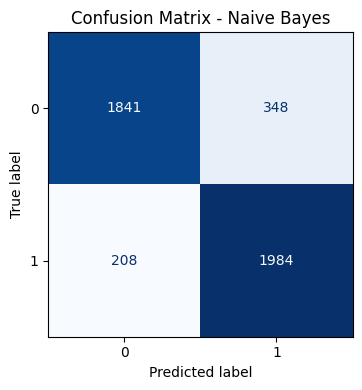


--- AdaBoost: 5-fold cross-validation on training set ---
[AdaBoost] 5-fold CV — Accuracy: 0.8215 ± 0.0072 | F1: 0.8213 ± 0.0073
===== AdaBoost =====
Accuracy  : 0.8213
Precision : 0.8227
Recall    : 0.8213
F1-score  : 0.8211
AUC       : 0.9000
Training Time: 60.38s

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.83      2189
           1       0.84      0.79      0.82      2192

    accuracy                           0.82      4381
   macro avg       0.82      0.82      0.82      4381
weighted avg       0.82      0.82      0.82      4381



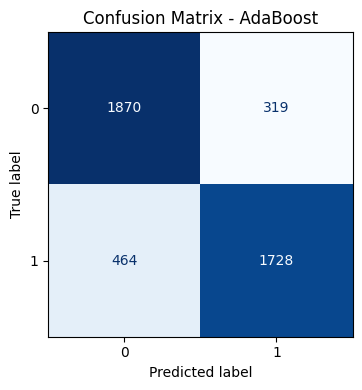


--- XGBoost: 5-fold cross-validation on training set ---
[XGBoost] 5-fold CV — Accuracy: 0.8625 ± 0.0041 | F1: 0.8625 ± 0.0041
===== XGBoost =====
Accuracy  : 0.8665
Precision : 0.8665
Recall    : 0.8665
F1-score  : 0.8665
AUC       : 0.9376
Training Time: 56.54s

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.87      2189
           1       0.86      0.87      0.87      2192

    accuracy                           0.87      4381
   macro avg       0.87      0.87      0.87      4381
weighted avg       0.87      0.87      0.87      4381



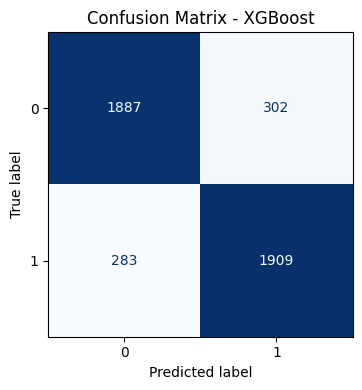


All classical ML models (except KNN) trained and evaluated.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from xgboost import XGBClassifier

ml_model_defs = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    # max_depth is capped here (not left unbounded) specifically to keep SHAP TreeExplainer
    # numerically stable later in Section 16 — fully unbounded trees on very high-dimensional,
    # very sparse TF-IDF data are a documented cause of SHAP's internal combinatorial
    # calculation overflowing to values like 1e28-1e34 (see shap/shap issue #4042). Bounded
    # depth avoids this with negligible accuracy cost.
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=20, random_state=SEED, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=SEED),
    "SVM (LinearSVC)": LinearSVC(random_state=SEED, max_iter=5000),
    "Naive Bayes": MultinomialNB(),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=SEED),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1),
}

for name, model in ml_model_defs.items():
    print(f"\n--- {name}: 5-fold cross-validation on training set ---")
    run_cv(model, X_train_tfidf, y_train, name)

    start = time.time()
    model.fit(X_train_tfidf, y_train)
    train_time = time.time() - start
    y_pred = model.predict(X_test_tfidf)
    y_score = get_positive_class_score(model, X_test_tfidf)

    evaluate_and_log(name, y_test, y_pred, train_time, category="ML", y_score=y_score)
    trained_ml_models[name] = model

print("\nAll classical ML models (except KNN) trained and evaluated.")


### 8.1 KNN — fixed with TruncatedSVD (LSA) dimensionality reduction

Explained variance retained by 200 SVD components: 0.216

--- KNN (on SVD-reduced features): 5-fold cross-validation ---
[KNN (SVD)] 5-fold CV — Accuracy: 0.6599 ± 0.0072 | F1: 0.6284 ± 0.0094
===== KNN (TF-IDF+SVD) =====
Accuracy  : 0.6469
Precision : 0.7330
Recall    : 0.6469
F1-score  : 0.6111
AUC       : 0.8189
Training Time: 0.00s

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.95      0.73      2189
           1       0.87      0.34      0.49      2192

    accuracy                           0.65      4381
   macro avg       0.73      0.65      0.61      4381
weighted avg       0.73      0.65      0.61      4381



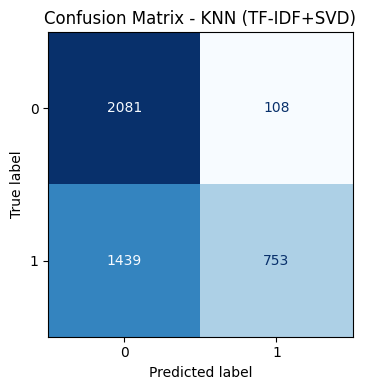

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

SVD_COMPONENTS = 200
svd = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=SEED)
X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)
print(f"Explained variance retained by {SVD_COMPONENTS} SVD components: "
      f"{svd.explained_variance_ratio_.sum():.3f}")

knn_model = KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1)

print("\n--- KNN (on SVD-reduced features): 5-fold cross-validation ---")
run_cv(knn_model, X_train_svd, y_train, "KNN (SVD)")

start = time.time()
knn_model.fit(X_train_svd, y_train)
train_time = time.time() - start
y_pred_knn = knn_model.predict(X_test_svd)
y_score_knn = get_positive_class_score(knn_model, X_test_svd)

evaluate_and_log("KNN (TF-IDF+SVD)", y_test, y_pred_knn, train_time, category="ML", y_score=y_score_knn)
trained_ml_models["KNN (TF-IDF+SVD)"] = knn_model
# [v7 FIX] D: removed a hard-coded "~0.50 accuracy" claim about a raw-TF-IDF KNN run that this
# notebook never performs. Run KNN on X_train_tfidf separately if you want to report that comparison.


### 8.2 ML model comparison

                 Model Category  Accuracy  Precision    Recall  F1-score  \
0  Logistic Regression       ML  0.881306   0.881378  0.881306  0.881301   
1          Naive Bayes       ML  0.873088   0.874613  0.873088  0.872956   
2      SVM (LinearSVC)       ML  0.871947   0.871996  0.871947  0.871943   
3              XGBoost       ML  0.866469   0.866496  0.866469  0.866466   
4        Random Forest       ML  0.852089   0.852185  0.852089  0.852079   
5             AdaBoost       ML  0.821274   0.822696  0.821274  0.821082   
6        Decision Tree       ML  0.757361   0.757415  0.757361  0.757350   
7     KNN (TF-IDF+SVD)       ML  0.646884   0.732976  0.646884  0.611074   

        AUC  Training Time (s)  
0  0.944120           0.227238  
1  0.938970           0.009453  
2  0.937288           0.197253  
3  0.937615          50.939626  
4  0.924863           8.468345  
5  0.899953          54.137160  
6  0.751687           6.366658  
7  0.818934           0.004024  


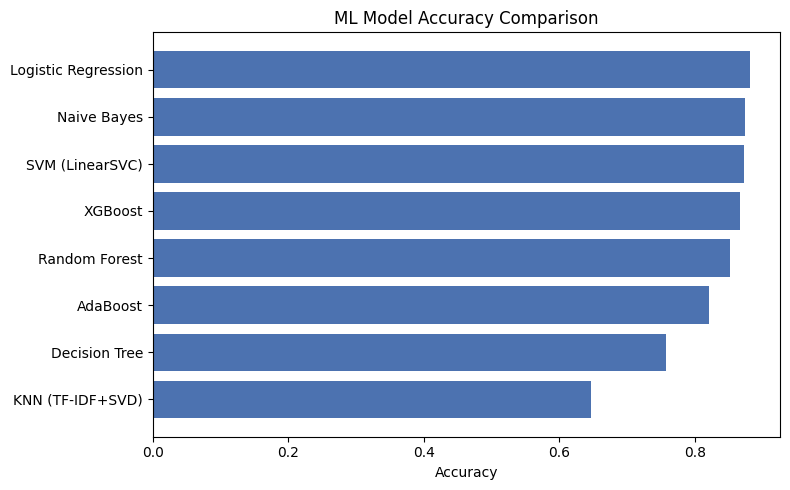

In [ ]:
ml_results_df = pd.DataFrame(all_results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
print(ml_results_df)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(ml_results_df["Model"], ml_results_df["Accuracy"], color="#4C72B0")
ax.invert_yaxis()
ax.set_title("ML Model Accuracy Comparison")
ax.set_xlabel("Accuracy")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/ml_accuracy_comparison.png", dpi=150)
plt.show()


## 9. Deep Learning models — LSTM & BiLSTM



In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

VOCAB_SIZE = 15000
MAX_LEN = 120
NUM_CLASSES = len(le.classes_)

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post")

print(f"Padded train shape: {X_train_pad.shape} | test shape: {X_test_pad.shape} | vocab: {VOCAB_SIZE}")
print("DL feature prep complete.")


In [ ]:
def plot_training_curves(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history.history["accuracy"], label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title(f"{model_name} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history.history["loss"], label="Train")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title(f"{model_name} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    safe_name = re.sub(r"[^\w\-]", "_", model_name)
    plt.savefig(f"{OUTPUT_DIR}/figures/{safe_name}_training_curves.png", dpi=150)
    plt.show()
    plt.close(fig)


### 9.1 LSTM — fixed (more epochs, early stopping, LR scheduling)

In [ ]:
def build_lstm_model():
    model = Sequential([
        Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=MAX_LEN),
        SpatialDropout1D(0.3),
        LSTM(128, dropout=0.3, recurrent_dropout=0.2),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

lstm_model = build_lstm_model()
lstm_model.summary()

lstm_callbacks = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
]

start = time.time()
lstm_history = lstm_model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=20, batch_size=64,
    callbacks=lstm_callbacks, verbose=1,
)
lstm_train_time = time.time() - start
print(f"\nLSTM training time: {lstm_train_time:.2f}s (stopped early at epoch "
      f"{len(lstm_history.history['loss'])} of 20)")

plot_training_curves(lstm_history, "LSTM")


In [ ]:
y_pred_lstm_proba = lstm_model.predict(X_test_pad)
y_pred_lstm = np.argmax(y_pred_lstm_proba, axis=1)
y_score_lstm = y_pred_lstm_proba[:, POS_CLASS_IDX]
evaluate_and_log("LSTM", y_test, y_pred_lstm, lstm_train_time, category="DL", y_score=y_score_lstm)


### 9.2 BiLSTM — fixed (regularization + early stopping to control overfitting)

In [ ]:
def build_bilstm_model():
    model = Sequential([
        Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=MAX_LEN),
        SpatialDropout1D(0.4),
        Bidirectional(LSTM(96, dropout=0.4, recurrent_dropout=0.3,
                            kernel_regularizer=l2(1e-4))),
        Dense(64, activation="relu", kernel_regularizer=l2(1e-4)),
        Dropout(0.4),
        Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

bilstm_model = build_bilstm_model()
bilstm_model.summary()

bilstm_callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
]

start = time.time()
bilstm_history = bilstm_model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=20, batch_size=64,
    callbacks=bilstm_callbacks, verbose=1,
)
bilstm_train_time = time.time() - start
print(f"\nBiLSTM training time: {bilstm_train_time:.2f}s (stopped early at epoch "
      f"{len(bilstm_history.history['loss'])} of 20)")

plot_training_curves(bilstm_history, "BiLSTM")


In [ ]:
y_pred_bilstm_proba = bilstm_model.predict(X_test_pad)
y_pred_bilstm = np.argmax(y_pred_bilstm_proba, axis=1)
y_score_bilstm = y_pred_bilstm_proba[:, POS_CLASS_IDX]
evaluate_and_log("BiLSTM", y_test, y_pred_bilstm, bilstm_train_time, category="DL", y_score=y_score_bilstm)

# free GPU memory before the transformer stage
del lstm_model, bilstm_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
tf.keras.backend.clear_session()


## 10. Transformer — BanglaBERT fine-tuning

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

BERT_MODEL_NAME = "sagorsarker/bangla-bert-base"
BERT_MAX_LEN = 128
BERT_BATCH_SIZE = 16
BERT_EPOCHS = 4
USE_AMP = torch.cuda.is_available()

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME, num_labels=NUM_CLASSES
).to(DEVICE)

class BanglaDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx], truncation=True, padding="max_length",
            max_length=self.max_len, return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

# [v7 FIX] C: hold out 10% of the training set for validation (same share as the LSTM/BiLSTM
# validation_split=0.1), so the best epoch can be selected without touching the test set.
bert_tr_text, bert_val_text, bert_tr_y, bert_val_y = train_test_split(
    X_train_text, y_train, test_size=0.1, random_state=SEED, stratify=y_train
)
bert_train_ds = BanglaDataset(bert_tr_text, bert_tr_y, bert_tokenizer, BERT_MAX_LEN)
bert_val_ds = BanglaDataset(bert_val_text, bert_val_y, bert_tokenizer, BERT_MAX_LEN)
bert_test_ds = BanglaDataset(X_test_text, y_test, bert_tokenizer, BERT_MAX_LEN)
bert_train_loader = DataLoader(bert_train_ds, batch_size=BERT_BATCH_SIZE, shuffle=True)
bert_val_loader = DataLoader(bert_val_ds, batch_size=BERT_BATCH_SIZE, shuffle=False)
bert_test_loader = DataLoader(bert_test_ds, batch_size=BERT_BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(bert_train_loader)} | Val batches: {len(bert_val_loader)} | "
      f"Test batches: {len(bert_test_loader)}")

# [v7 FIX] C: report how many posts are cut off at BERT_MAX_LEN sub-word tokens
bert_token_lens = np.array([len(ids) for ids in bert_tokenizer(list(X_train_text), truncation=False)["input_ids"]])
print(f"BanglaBERT sub-word tokens per training post: median {np.median(bert_token_lens):.0f}, "
      f"90th pct {np.percentile(bert_token_lens, 90):.0f}; "
      f"{(bert_token_lens > BERT_MAX_LEN).mean() * 100:.1f}% of posts are truncated at {BERT_MAX_LEN}")

optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5)
total_steps = len(bert_train_loader) * BERT_EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
print("Mixed precision enabled:", USE_AMP)


In [ ]:
def train_one_epoch(model, loader, optimizer, scheduler, scaler, device, use_amp):
    model.train()
    total_loss = 0.0
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=use_amp):
            outputs = model(**batch)
            loss = outputs.loss
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item()
    return total_loss / len(loader)

@torch.no_grad()
def evaluate_bert_model(model, loader, device):
    """Returns true labels, hard predictions, and softmax probabilities (for ROC/PR/AUC)."""
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    for batch in loader:
        labels = batch.pop("labels").to(device)
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        probs = F.softmax(outputs.logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

# [v7 FIX] C: evaluate on the validation set after every epoch and keep the best-epoch weights
# (lowest validation loss), mirroring EarlyStopping(restore_best_weights=True) on the RNNs.
best_val_loss, best_epoch, best_state = np.inf, None, None
start = time.time()
for epoch in range(BERT_EPOCHS):
    epoch_start = time.time()
    avg_loss = train_one_epoch(bert_model, bert_train_loader, optimizer, scheduler, scaler, DEVICE, USE_AMP)
    val_true, val_pred, val_probs = evaluate_bert_model(bert_model, bert_val_loader, DEVICE)
    val_loss = float(-np.mean(np.log(np.clip(val_probs[np.arange(len(val_true)), val_true], 1e-12, 1.0))))
    val_acc = float(np.mean(val_pred == val_true))
    print(f"Epoch {epoch + 1}/{BERT_EPOCHS} - loss: {avg_loss:.4f} - val_loss: {val_loss:.4f} - "
          f"val_acc: {val_acc:.4f} - time: {time.time() - epoch_start:.1f}s")
    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch + 1
        best_state = {k: v.detach().cpu().clone() for k, v in bert_model.state_dict().items()}
bert_train_time = time.time() - start
bert_model.load_state_dict(best_state)
print(f"Restored BanglaBERT weights from epoch {best_epoch} (val_loss={best_val_loss:.4f})")
print(f"\nTotal BanglaBERT training time: {bert_train_time:.2f}s")

y_test_bert, bert_pred, bert_probs = evaluate_bert_model(bert_model, bert_test_loader, DEVICE)
y_score_bert = bert_probs[:, POS_CLASS_IDX]
evaluate_and_log("BanglaBERT", y_test_bert, bert_pred, bert_train_time, category="Transformer", y_score=y_score_bert)

os.makedirs("models/banglabert_model", exist_ok=True)
bert_model.save_pretrained("models/banglabert_model")
bert_tokenizer.save_pretrained("models/banglabert_model")
print("BanglaBERT model and tokenizer saved to 'models/banglabert_model'.")


## 11. Final model comparison table (ML + DL + Transformer, incl. AUC)

In [ ]:
final_comparison_df = pd.DataFrame(all_results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
print(final_comparison_df)
final_comparison_df.to_csv(f"{OUTPUT_DIR}/tables/final_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
cat_colors = {"ML": "#4C72B0", "DL": "#55A868", "Transformer": "#C44E52"}
colors = final_comparison_df["Category"].map(cat_colors)
ax.barh(final_comparison_df["Model"], final_comparison_df["Accuracy"], color=colors)
ax.invert_yaxis()
ax.set_title("Accuracy Comparison — All Models (ML / DL / Transformer)")
ax.set_xlabel("Accuracy")
for i, v in enumerate(final_comparison_df["Accuracy"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/final_accuracy_comparison.png", dpi=150)
plt.show()

best_overall = final_comparison_df.iloc[0]
print(f"\nBest overall model: {best_overall['Model']} (Accuracy={best_overall['Accuracy']:.4f}, "
      f"AUC={best_overall['AUC']:.4f})")


### 11.1 Final results table as a clean image



In [ ]:
table_df = final_comparison_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1-score", "AUC"]:
    table_df[col] = table_df[col].map(lambda x: f"{x:.4f}")
table_df["Training Time (s)"] = table_df["Training Time (s)"].map(lambda x: f"{x:.2f}")

fig, ax = plt.subplots(figsize=(11, 0.5 + 0.4 * len(table_df)))
ax.axis("off")
tbl = ax.table(
    cellText=table_df.values, colLabels=table_df.columns,
    cellLoc="center", loc="center"
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.5)

for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold", color="white")
        cell.set_facecolor("#4C72B0")
    else:
        cell.set_facecolor("#F2F2F2" if row % 2 == 0 else "white")

plt.title("Final Model Comparison — Accuracy, Precision, Recall, F1-score, AUC", fontsize=12, pad=20)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/tables/final_results_table.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved final results table image to '{OUTPUT_DIR}/tables/final_results_table.png'")


## 12. ROC curves + AUC (all models)

In [ ]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 7))
palette = plt.cm.tab20(np.linspace(0, 1, len(score_lookup)))

for (name, y_score), color in zip(score_lookup.items(), palette):
    # BanglaBERT/DL models were evaluated on their own y_test copies; they should match y_test exactly
    y_true_for_model = y_test_bert if name == "BanglaBERT" else y_test
    fpr, tpr, _ = roc_curve(y_true_for_model, y_score)
    auc_val = roc_auc_score(y_true_for_model, y_score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})", color=color, linewidth=1.5)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_pr/roc_curves_all_models.png", dpi=150)
plt.show()


## 13. Precision–Recall curves (all models)




In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 7))

for (name, y_score), color in zip(score_lookup.items(), palette):
    y_true_for_model = y_test_bert if name == "BanglaBERT" else y_test
    precision, recall, _ = precision_recall_curve(y_true_for_model, y_score)
    ap = average_precision_score(y_true_for_model, y_score)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})", color=color, linewidth=1.5)

baseline_rate = np.mean(y_test == POS_CLASS_IDX)
plt.axhline(baseline_rate, linestyle="--", color="gray", linewidth=1,
            label=f"Random baseline (AP={baseline_rate:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves — All Models")
plt.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_pr/pr_curves_all_models.png", dpi=150)
plt.show()


## 14. Statistical significance — McNemar's test



In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

top2 = final_comparison_df.iloc[:2]
name_a, name_b = top2.iloc[0]["Model"], top2.iloc[1]["Model"]
preds_a, preds_b = prediction_lookup[name_a], prediction_lookup[name_b]

y_true_a = y_test_bert if name_a == "BanglaBERT" else y_test
y_true_b = y_test_bert if name_b == "BanglaBERT" else y_test
assert np.array_equal(y_true_a, y_true_b), "Test label ordering mismatch between models."
y_true_common = y_true_a

correct_a = (preds_a == y_true_common)
correct_b = (preds_b == y_true_common)
n_a_only = int(np.sum(correct_a & ~correct_b))
n_b_only = int(np.sum(~correct_a & correct_b))

contingency = [[0, n_a_only], [n_b_only, 0]]
result = mcnemar(contingency, exact=(n_a_only + n_b_only < 25))

print(f"Comparing top 2 models: '{name_a}' vs '{name_b}'")
print(f"'{name_a}' correct only: {n_a_only} | '{name_b}' correct only: {n_b_only}")
print(f"McNemar statistic: {result.statistic:.4f} | p-value: {result.pvalue:.4f}")
if result.pvalue < 0.05:
    print("=> Difference IS statistically significant (p < 0.05).")
else:
    print("=> Difference is NOT statistically significant at p < 0.05 — "
          "report both models' scores as effectively comparable in your thesis.")


## 15. Error analysis on the best model

In [ ]:
best_model_name = final_comparison_df.iloc[0]["Model"]
best_preds = prediction_lookup[best_model_name]
best_y_true = y_test_bert if best_model_name == "BanglaBERT" else y_test
best_text_source = X_test_text  # same order for all models

test_df = pd.DataFrame({
    "text": best_text_source,
    "true_label": best_y_true,
    "pred_label": best_preds,
})
misclassified = test_df[test_df["true_label"] != test_df["pred_label"]]
print(f"Best model: {best_model_name}")
print(f"Misclassified: {len(misclassified)} / {len(test_df)} ({len(misclassified)/len(test_df)*100:.1f}%)")

pd.set_option("display.max_colwidth", 120)
sample_errors = misclassified.sample(min(10, len(misclassified)), random_state=SEED)
print(sample_errors)
sample_errors.to_csv(f"{OUTPUT_DIR}/tables/{re.sub(r'[^\w-]','_',best_model_name)}_misclassified_sample.csv", index=False)


## 16. Explainability — SHAP (with Bangla font support)


In [ ]:
import shap

def to_2class_proba(model, X):
    """Always returns an (n_samples, 2) probability-like array, regardless of whether the
    model exposes predict_proba (LogReg, RF, NB, XGB, AdaBoost, KNN) or only decision_function
    (LinearSVC). This avoids shape-mismatch errors in SHAP/LIME downstream."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)
    scores = model.decision_function(X)
    scores = np.atleast_2d(scores).T if np.ndim(scores) == 1 else scores
    if scores.shape[1] == 1:
        scores = np.hstack([-scores, scores])
    exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True))
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)

ml_only = final_comparison_df[final_comparison_df["Category"] == "ML"].reset_index(drop=True)
best_ml_model_name = ml_only.iloc[0]["Model"]
best_ml_model = trained_ml_models[best_ml_model_name]
print(f"Model selected for explainability: {best_ml_model_name} "
      f"(Test accuracy: {ml_only.iloc[0]['Accuracy']:.4f})")

feature_names = tfidf_vectorizer.get_feature_names_out()
predict_fn = lambda X: to_2class_proba(best_ml_model, X)

tree_based = ("Random Forest", "Decision Tree", "XGBoost", "AdaBoost")
linear_based = ("Logistic Regression", "SVM (LinearSVC)")  # [v7 FIX] F
X_sample = X_test_tfidf[:100]
shap_values_raw, explainer, explainer_type = None, None, None

# SHAP values for a well-behaved binary classifier should be small — typically well under 10
# even in raw-margin space. Anything far beyond this (e.g. >= 1e6) signals the known Tree-SHAP
# numerical-overflow issue on high-dimensional sparse data, not a genuine explanation.
SHAP_SANITY_THRESHOLD = 1e6

def shap_values_look_sane(values):
    try:
        return np.all(np.isfinite(values)) and np.max(np.abs(values)) < SHAP_SANITY_THRESHOLD
    except Exception:
        return False

try:
    if best_ml_model_name in tree_based:
        explainer = shap.TreeExplainer(best_ml_model)
        # check_additivity=False avoids the common "Additivity check failed" ValueError that
        # tree ensembles trigger due to floating-point rounding — this is the standard fix.
        shap_values_raw = explainer.shap_values(X_sample.toarray(), check_additivity=False)
        explainer_type = "TreeExplainer"

        if not shap_values_look_sane(shap_values_raw):
            print("WARNING: TreeExplainer produced abnormally large SHAP values "
                  "(the known sparse-high-dimensional-data overflow issue). "
                  "Retrying with feature_perturbation='interventional' and a background sample...")
            bg_sample = shap.sample(X_train_tfidf[:2000].toarray(), 100, random_state=SEED)
            explainer = shap.TreeExplainer(
                best_ml_model, data=bg_sample, feature_perturbation="interventional"
            )
            shap_values_raw = explainer.shap_values(X_sample.toarray(), check_additivity=False)
            explainer_type = "TreeExplainer (interventional)"

            if not shap_values_look_sane(shap_values_raw):
                raise ValueError(
                    "SHAP values remained numerically unstable even after retry. "
                    "Consider lowering max_depth further for this model in Section 8."
                )
    elif best_ml_model_name in linear_based:
        # [v7 FIX] F: LinearExplainer is exact for linear models (KernelExplainer with nsamples=100
        # cannot approximate 8,000 features reliably). Values are in log-odds (LogReg) or
        # decision-margin (LinearSVC) units, background = training-set feature means.
        explainer = shap.LinearExplainer(best_ml_model, X_train_tfidf)
        shap_values_raw = explainer.shap_values(X_sample)
        explainer_type = "LinearExplainer"
    else:
        kmeans_bg = shap.kmeans(X_train_tfidf[:2000].toarray(), 20)  # subsample before densifying, keeps memory low
        explainer = shap.KernelExplainer(predict_fn, kmeans_bg)
        shap_values_raw = explainer.shap_values(X_sample.toarray(), nsamples=100)
        explainer_type = "KernelExplainer"

    print(f"Using shap.{explainer_type} for '{best_ml_model_name}'.")
    SHAP_AVAILABLE = True
except Exception as e:
    print(f"SHAP explainer failed with: {type(e).__name__}: {e}")
    print("Skipping SHAP plots (Sections 16.1-16.3) — LIME (Section 17) is independent and will still run.")
    SHAP_AVAILABLE = False


In [ ]:
def get_class_shap_values(shap_values_raw, class_idx):
    if isinstance(shap_values_raw, list):
        return shap_values_raw[class_idx]
    arr = np.array(shap_values_raw)
    if arr.ndim == 3:
        return arr[:, :, class_idx]
    return arr

EXPLAIN_CLASS_IDX = min(1, NUM_CLASSES - 1)
CLASS_NAMES = [str(c) for c in le.classes_]
safe_name = re.sub(r"[^\w\-]", "_", best_ml_model_name)

if SHAP_AVAILABLE:
    print(f"Explaining class: '{CLASS_NAMES[EXPLAIN_CLASS_IDX]}' (index {EXPLAIN_CLASS_IDX})")
    class_shap_values = get_class_shap_values(shap_values_raw, EXPLAIN_CLASS_IDX)
    print("SHAP values shape for explained class:", np.array(class_shap_values).shape)
else:
    print("SHAP was unavailable (see Section 16 message above) — skipping.")


### 16.1 Global feature importance — SHAP summary plot

In [ ]:
if SHAP_AVAILABLE:
    plt.figure()
    shap.summary_plot(
        class_shap_values, X_sample.toarray(), feature_names=feature_names,
        show=False, max_display=15
    )
    plt.title(f"SHAP Summary — {best_ml_model_name} (class: {CLASS_NAMES[EXPLAIN_CLASS_IDX]})")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/shap/{safe_name}_summary_global.png", dpi=150, bbox_inches="tight")
    plt.show()

    mean_abs_shap = np.abs(class_shap_values).mean(axis=0)
    shap_importance_df = pd.DataFrame({
        "feature": feature_names, "mean_abs_shap": mean_abs_shap
    }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    shap_importance_df.to_csv(f"{OUTPUT_DIR}/shap/{safe_name}_global_importance.csv", index=False)
    print("Top 10 features by mean |SHAP value|:")
    print(shap_importance_df.head(10))
else:
    shap_importance_df = pd.DataFrame(columns=["feature", "mean_abs_shap"])
    print("Skipped (SHAP unavailable).")


### 16.2 Global feature importance — bar chart

In [ ]:
if SHAP_AVAILABLE and len(shap_importance_df) > 0:
    top_n = shap_importance_df.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(top_n["feature"], top_n["mean_abs_shap"], color="#1f77b4")
    ax.set_title(f"SHAP Global Feature Importance — {best_ml_model_name}")
    ax.set_xlabel("mean(|SHAP value|)")
    # Bangla feature-name y-tick labels render correctly automatically via the global
    # font-fallback list set in Section 2 — no per-label override needed.
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/shap/{safe_name}_global_importance_bar.png", dpi=150)
    plt.show()
else:
    print("Skipped (SHAP unavailable).")


### 16.3 Individual prediction — SHAP waterfall plot

In [ ]:
if SHAP_AVAILABLE:
    SAMPLE_IDX = 5  # index within X_sample (0-99)

    if isinstance(explainer.expected_value, (list, np.ndarray)):
        base_value = np.array(explainer.expected_value).flatten()[EXPLAIN_CLASS_IDX]
    else:
        base_value = explainer.expected_value

    sample_shap_vals = class_shap_values[SAMPLE_IDX]
    sample_features = X_sample[SAMPLE_IDX].toarray().flatten()

    explanation = shap.Explanation(
        values=sample_shap_vals,
        base_values=base_value,
        data=sample_features,
        feature_names=feature_names,
    )

    plt.figure()
    shap.plots.waterfall(explanation, max_display=15, show=False)
    plt.title(f"SHAP Waterfall — {best_ml_model_name} (Test Sample #{SAMPLE_IDX})")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/shap/{safe_name}_waterfall_sample{SAMPLE_IDX}.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Skipped (SHAP unavailable).")


## 17. Explainability — LIME (with Bangla text support)

In [ ]:
from lime.lime_text import LimeTextExplainer

# Reuses the same to_2class_proba() helper defined in Section 16, so SHAP and LIME are
# guaranteed to be explaining identical probability outputs for the same model.
def bangla_predict_proba(texts):
    X = tfidf_vectorizer.transform(texts)
    return to_2class_proba(best_ml_model, X)

lime_explainer = LimeTextExplainer(
    class_names=CLASS_NAMES,
    split_expression=r"\s+",   # whitespace-only split preserves Bangla word boundaries
    bow=True,
)

N_LIME_SAMPLES = 5
rng = np.random.RandomState(SEED)
lime_sample_idx = rng.choice(len(X_test_text), size=N_LIME_SAMPLES, replace=False)

lime_summary_rows = []
for rank, idx in enumerate(lime_sample_idx, start=1):
    text_instance = X_test_text[idx]
    true_label = int(y_test[idx])

    exp = lime_explainer.explain_instance(
        text_instance, bangla_predict_proba, num_features=10, num_samples=500
    )
    pred_label = int(np.argmax(bangla_predict_proba([text_instance])[0]))
    pred_proba = float(bangla_predict_proba([text_instance])[0][pred_label])

    print(f"\n===== LIME Explanation {rank}/{N_LIME_SAMPLES} (test index {idx}) =====")
    print(f"Text (truncated): {text_instance[:150]}")
    print(f"True label      : {true_label}")
    print(f"Predicted label : {pred_label}")
    print(f"Prediction probability: {pred_proba:.4f}")

    weights = exp.as_list()
    positive_words = sorted([w for w in weights if w[1] > 0], key=lambda x: -x[1])[:5]
    negative_words = sorted([w for w in weights if w[1] < 0], key=lambda x: x[1])[:5]
    print(f"Top positive contributing words: {positive_words}")
    print(f"Top negative contributing words: {negative_words}")

    exp.save_to_file(f"{OUTPUT_DIR}/lime/lime_explanation_{rank}.html")
    lime_summary_rows.append({
        "test_index": idx, "true_label": true_label, "pred_label": pred_label,
        "pred_proba": pred_proba, "top_positive_words": positive_words, "top_negative_words": negative_words,
    })

pd.DataFrame(lime_summary_rows).to_csv(f"{OUTPUT_DIR}/lime/lime_explanations_summary.csv", index=False)
print(f"\nSaved {N_LIME_SAMPLES} LIME HTML explanations to '{OUTPUT_DIR}/lime/' "
      f"and a summary CSV to '{OUTPUT_DIR}/lime/lime_explanations_summary.csv'.")


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
for name, obj in list(globals().items()):
    if isinstance(obj, (TfidfVectorizer, LogisticRegression)):
        print(name, type(obj).__name__)

tfidf_vectorizer TfidfVectorizer


In [ ]:
import sklearn, inspect
from sklearn.linear_model import LogisticRegression

print("sklearn version:", sklearn.__version__)

# 1) Kon dictionary/list er bhitore LogisticRegression ache
for name, obj in list(globals().items()):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if isinstance(v, LogisticRegression):
                print(f"dict '{name}' -> key {k!r}")
            elif hasattr(v, "steps"):  # Pipeline hole
                for step_name, step in v.steps:
                    if isinstance(step, LogisticRegression):
                        print(f"dict '{name}' -> key {k!r} (Pipeline, step {step_name!r})")

# 2) Tomader LIME e jei function use hoyeche, tar code
for fn in ["bangla_predict_proba", "clean_text", "clean_bangla_text"]:
    if fn in globals():
        print("\n=====", fn, "=====")
        print(inspect.getsource(globals()[fn]))

sklearn version: 1.6.1
dict 'trained_ml_models' -> key 'Logistic Regression'
dict 'ml_model_defs' -> key 'Logistic Regression'

===== clean_bangla_text =====
def clean_bangla_text(text: str) -> str:
    text = str(text)
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+\.\s*", " ", text)
    text = re.sub(r"#(\w+)", " ", text)
    # [v7 FIX] B: also keep ZWNJ/ZWJ (U+200C/U+200D), which Bangla needs for forms like র‍্য
    text = re.sub(r"[^\u0980-\u09FF\u200c\u200d\s\u0964\d,.!?]", " ", text)  # keep Bangla script, digits, basic punctuation
    text = re.sub(r"\s+", " ", text).strip()
    return text



In [ ]:
import joblib
from google.colab import files

lr_fitted = trained_ml_models["Logistic Regression"]

# Sanity check: model ta fitted kina
print("Fitted:", hasattr(lr_fitted, "coef_"))
print("Features TF-IDF:", len(tfidf_vectorizer.get_feature_names_out()),
      "| LR expects:", lr_fitted.coef_.shape[1])

joblib.dump(tfidf_vectorizer, "tfidf.pkl")
joblib.dump(lr_fitted, "lr.pkl")
files.download("tfidf.pkl")
files.download("lr.pkl")

Fitted: True
Features TF-IDF: 8000 | LR expects: 8000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np, pandas as pd
for n, o in list(globals().items()):
    if n.startswith("_"):
        continue
    try:
        if isinstance(o, (pd.Series, list, np.ndarray)) and len(o) == 4381:
            print(n, type(o).__name__)
    except Exception:
        pass

X_test_text ndarray
y_test ndarray
y_pred ndarray
y_score ndarray


In [ ]:
import numpy as np

lr_fitted = trained_ml_models["Logistic Regression"]
texts = np.asarray(X_test_text, dtype=object)
y_true = np.asarray(y_test).astype(int)

proba = lr_fitted.predict_proba(tfidf_vectorizer.transform(texts))
pred = proba.argmax(axis=1)

# Sanity check: thesis e 0.8813 chilo
print("Test size:", len(texts), "| LR accuracy:", round(float((pred == y_true).mean()), 4))

# Demo er jonno chhoto post (80 theke 400 character)
lens = np.array([len(t) for t in texts])
short = (lens >= 80) & (lens <= 400)
rng = np.random.default_rng(42)

def show(title, mask, k):
    idx = np.where(mask & short)[0]
    idx = rng.choice(idx, size=min(k, len(idx)), replace=False)
    print(f"\n########## {title} ##########")
    for i in idx:
        print(f"\n[test index {i}] true={y_true[i]} | P(Depressed)={proba[i][1]:.4f}")
        print(texts[i])

show("Depressed, model THIK dhorche",     (y_true == 1) & (pred == 1), 3)
show("Non-Depressed, model THIK dhorche", (y_true == 0) & (pred == 0), 3)
show("Model BHUL korche",                 (y_true != pred), 2)

Test size: 4381 | LR accuracy: 0.8813

########## Depressed, model THIK dhorche ##########

[test index 2867] true=1 | P(Depressed)=0.7862
থেরাপিস্ট পেয়েছি সাথে দ্বিতীয় অ্যাপয়েন্টমেন্ট জিজ্ঞাসা খুলতে ধীর বলেছিলাম সম্ভবত যাইহোক পাবে একটু কীভাবে জীবন মরে ভাল সম্পর্কে বললাম কুত্তাটি স্বার্থপর মরতে চাওয়ার কাপুরুষ প্রমাণ বুঝতে পারছেন থেরাপিস্টের সাথে কীভাবে সাহায্য জানার ভান অসুস্থ তৃতীয়বার ছেড়ে থেরাপিস্ট অকেজো

[test index 475] true=1 | P(Depressed)=0.9264
বিন্দু জানি মনোযোগ সম্ভবত উচ্চারণ উভয় উপায়ে ভাল আসে আগের বিষণ্ণ ক্লাস্ট্রোফোবিক বোধ ক্লান্ত বোধ করছি পৃথিবীতে সম্পূর্ণ একা অনুভব চিন্তা ঘৃণা চিন্তাভাবনা একা থাকি বিপজ্জনক শিকারীদের ভরা অন্ধকার ঘরে হাঁটছি পিছনে দরজা বন্ধ দিচ্ছি জানি পোস্ট চালিয়ে যাচ্ছি

[test index 3460] true=1 | P(Depressed)=0.7517
ভয় কাটিয়ে উঠি আরাম জোন বেরিয়ে যাই অবশেষে থেরাপিতে যাই মাদক সেবন অবৈধভাবে টাকা কামাই মাদক বিক্রি সাইক্যাট্রি কারাগারে আটকে রাখবে দুটোই বলবো পরবর্তী পদক্ষেপ সত্যি কথা পরবর্তী পদক্ষেপ বিশ্ববিদ্যালয়ে স্বাভাবিক মাদক বাস্তবতা বাঁচতে কঠি

In [ ]:
import numpy as np
from google.colab import files

lr_fitted = trained_ml_models["Logistic Regression"]
rng = np.random.default_rng(7)

# Gali, suicide, self-harm, mathok er shobdo ache emon post bad
AVOID = ["আত্মহত্যা", "মরতে", "মরে ", "হত্যা", "ফাকিং", "চোদ", "বিষ্ঠা", "মাদক"]
def ok(t): return not any(w in t for w in AVOID)

def pick(texts, y, tag, n_each=5):
    texts = np.asarray(texts, dtype=object)
    y = np.asarray(y).astype(int)
    proba = lr_fitted.predict_proba(tfidf_vectorizer.transform(texts))
    pred = proba.argmax(axis=1)
    L = np.array([len(t) for t in texts])
    base = (L >= 80) & (L <= 400) & np.array([ok(t) for t in texts])
    out = []
    for title, mask in [("Depressed, model THIK", (y == 1) & (pred == 1)),
                        ("Non-Depressed, model THIK", (y == 0) & (pred == 0)),
                        ("Model BHUL", (y != pred))]:
        idx = np.where(mask & base)[0]
        idx = rng.choice(idx, size=min(n_each, len(idx)), replace=False)
        out.append(f"\n########## {tag.upper()} | {title} ##########")
        for i in idx:
            out.append(f"\n[{tag} index {i}] true={y[i]} | P(Depressed)={proba[i][1]:.4f}\n{texts[i]}")
    return "\n".join(out)

result = pick(X_test_text, y_test, "test")
if "X_train_text" in globals() and "y_train" in globals():
    result += "\n\n" + pick(X_train_text, y_train, "train", n_each=3)
else:
    print("X_train_text / y_train nai, shudhu test post nilam.")

with open("demo_posts.txt", "w", encoding="utf-8") as f:
    f.write(result)
print(result)
files.download("demo_posts.txt")


########## TEST | Depressed, model THIK ##########

[test index 2784] true=1 | P(Depressed)=0.9638
পুরো পরিবার বন্ধুরা জানে জীবন শেষ চাই মৃত্যু ভালবাসি বেঁচে থাকার ক্ষমতায় সবকিছু সাথে শিশুর কথা খারাপ তোলে অনুভব টাইপোর দুঃখিত সিস্টেমে ওষুধ বাচ্চা

[test index 3015] true=1 | P(Depressed)=0.8875
বিভ্রান্তিতে আছি ট্রমা খারাপ জিনিসের সম্মুখীন টেনশনহতাশাগ্রস্ত চারপাশে অন্ধকার পাচ্ছি ভবিষ্যতের আলো পাচ্ছি আশাহীনলক্ষ্যহীন ছাড়াই দুর্বিষহ জীবনযাপন করছি আমিও বেঁচে আছি বেঁচে থাকতে বাধ্য হচ্ছি জানি টিভি আকর্ষণীয় পর্ব দেখায় সুইচ বন্ধ দুর্বিষহ জীবন যাপন বাধ্য হচ্ছি

[test index 4140] true=1 | P(Depressed)=0.9664
ব্যাপার কতটা অনুভব অন্যদের কঠিন বাহক সম্পর্ক কতটা কঠিন কতটা অপেক্ষা ধৈর্য্য প্রদর্শন ব্যাপার আক্ষরিকভাবে বিধ্বস্ত বোধ করছি প্রত্যাখ্যানের প্রত্যাখ্যান স্ত্রীর শীতলতা পৃথিবীর শেষ প্রান্তে আছি হেরে অনুভূতি মেরে ফেলছে মারা সময় নিজেকে হেরে চাই নিজেকে জয়ী চাই জীবনের জীবনের প্রতিটি ব্যর্থ অনুভূতি ভয়াবহ

[test index 2561] true=1 | P(Depressed)=0.9067
কাঁদতে চাই শরীর ছেড়ে সৃজনশীলতা অনুভব ক্লা

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np

lr_fitted = trained_ml_models["Logistic Regression"]
texts = np.asarray(X_test_text, dtype=object)
y_true = np.asarray(y_test).astype(int)
pred = lr_fitted.predict(tfidf_vectorizer.transform(texts))

n_words = np.array([len(t.split()) for t in texts])
bins = [(1, 14), (15, 39), (40, 103), (104, 10**6)]
for lo, hi in bins:
    m = (n_words >= lo) & (n_words <= hi)
    if m.sum() > 0:
        print(f"{lo}-{hi} words: n={m.sum()}, accuracy={(pred[m] == y_true[m]).mean():.4f}")
print("Overall:", round(float((pred == y_true).mean()), 4))

1-14 words: n=35, accuracy=0.8286
15-39 words: n=1018, accuracy=0.8379
40-103 words: n=2210, accuracy=0.8995
104-1000000 words: n=1118, accuracy=0.8864
Overall: 0.8813


In [ ]:
import numpy as np

lr_fitted = trained_ml_models["Logistic Regression"]
texts = np.asarray(X_test_text, dtype=object)
y_true = np.asarray(y_test).astype(int)

X = tfidf_vectorizer.transform(texts).tocsr()
pred = lr_fitted.predict(X)
nnz = np.diff(X.indptr)   # ekta post e 8,000 feature er moddhe koyta ache

print("Posts with 0 features:", int((nnz == 0).sum()))
n_words = np.array([len(t.split()) for t in texts])
print("Correlation (word count vs features present):", round(float(np.corrcoef(n_words, nnz)[0, 1]), 3))

qs = np.unique(np.quantile(nnz, [0.25, 0.5, 0.75]))
grp = np.digitize(nnz, qs, right=True)
for g in np.unique(grp):
    m = grp == g
    print(f"group {g}: features present {nnz[m].min()}-{nnz[m].max()}, "
          f"n={m.sum()}, accuracy={(pred[m] == y_true[m]).mean():.4f}")
print("Overall:", round(float((pred == y_true).mean()), 4))

Posts with 0 features: 1
Correlation (word count vs features present): 0.959
group 0: features present 0-35, n=1153, accuracy=0.8517
group 1: features present 36-52, n=1040, accuracy=0.8875
group 2: features present 53-89, n=1100, accuracy=0.9027
group 3: features present 90-416, n=1088, accuracy=0.8851
Overall: 0.8813
